# 03 – Data analysis

Builds the analysis part of the report and one feature table per article for the classification.

1. Inventory level: diagnose breaks, build a daily stock series
2. Capital lockup over time (2016–2021) and coverage in days
3. Where the capital sits today (groups, Pareto)
4. Product type (derived from transactions: semi-finished / finished / retail)
5. ABC analysis (consumption value)
6. Demand patterns (ADI / CV², XYZ) and ABC-XYZ matrix
7. Dead and slow-moving stock
8. Lead time
9. Current reorder points and MOQ vs. actual demand
10. Save feature table

**Outputs:** figures in `outputs/figures/`, summary `outputs/tables/03_analysis_summary.txt`, `article_features.parquet`.
All money values are anonymised units (prices in the dataset are scaled).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

summary = []
def log(title, obj=""):
    text = obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else str(obj)
    block = f"\n=== {title} ===\n{text}"
    print(block)
    summary.append(block)

def savefig(name):
    plt.savefig(C.FIGURES / f"{name}.png")
    plt.show()

REF = pd.Timestamp(C.REFERENCE_DATE)
START, END = pd.Timestamp(C.ANALYSIS_START), pd.Timestamp(C.ANALYSIS_END)
DPY = C.DAYS_PER_YEAR

tx = pd.read_parquet(C.TRANSACTIONS_CLEAN)
art = pd.read_parquet(C.ARTICLES).set_index("article_nr")
dm = pd.read_parquet(C.DEMAND_MONTHLY)
price = art["last_direct_cost"]
log("Loaded", f"{len(tx):,} transactions | {len(art):,} inventory articles | reference date {REF.date()}")


=== Loaded ===
1,610,914 transactions | 1,751 inventory articles | reference date 2022-01-21


## 1. Inventory level – breaks and daily stock series

Within a day, the order of transactions is unknown. To stay order-independent we identify per article and day:
- **closing stock** = the `stock_after` value that is not the starting level of another transaction that day
- **opening stock** = the `inventory_level` value that is not the result of another transaction that day

Then: *within-day check* (opening + day's net quantity = closing) and *break check*
(opening of a day = closing of the previous transaction day).

In [2]:
t = tx[["article_nr", "date", "_row", "inventory_level", "quantity", "stock_after"]].copy()
t["k_before"] = (t["inventory_level"] * 100).round().astype("int64")
t["k_after"] = (t["stock_after"] * 100).round().astype("int64")

key_before = pd.MultiIndex.from_arrays([t["article_nr"], t["date"], t["k_before"]])
key_after = pd.MultiIndex.from_arrays([t["article_nr"], t["date"], t["k_after"]])
t["cand_close"] = ~key_after.isin(key_before)   # result not used as a start → end of chain
t["cand_open"] = ~key_before.isin(key_after)    # start not produced by another row → begin of chain

# file order looks newest-first: smaller _row = later in the day (used only as tie-breaker)
close = (t.sort_values(["article_nr", "date", "cand_close", "_row"], ascending=[True, True, True, False])
           .groupby(["article_nr", "date"]).tail(1)[["article_nr", "date", "stock_after"]])
opn = (t.sort_values(["article_nr", "date", "cand_open", "_row"], ascending=[True, True, True, True])
         .groupby(["article_nr", "date"]).tail(1)[["article_nr", "date", "inventory_level"]])
net = t.groupby(["article_nr", "date"], as_index=False)["quantity"].sum()

daily = (net.merge(opn, on=["article_nr", "date"]).merge(close, on=["article_nr", "date"])
            .rename(columns={"inventory_level": "opening", "stock_after": "closing", "quantity": "net"})
            .sort_values(["article_nr", "date"]))
daily["within_ok"] = np.isclose(daily["opening"] + daily["net"], daily["closing"], atol=0.05)
daily["prev_closing"] = daily.groupby("article_nr")["closing"].shift()
daily["gap"] = daily["opening"] - daily["prev_closing"]
has_prev = daily["prev_closing"].notna()
is_break = has_prev & (daily["gap"].abs() > 0.05)

typical = daily.groupby("article_nr")["closing"].apply(lambda x: x.abs().median()).replace(0, np.nan)
rel_gap = (daily.loc[is_break, "gap"].abs() / daily.loc[is_break, "article_nr"].map(typical))

log("Daily stock reconstruction", pd.Series({
    "article-days": f"{len(daily):,}",
    "within-day consistent (opening + net = closing)": f"{daily['within_ok'].mean():.1%}",
    "day transitions with a break": f"{is_break[has_prev].mean():.1%}",
    "articles with at least one break": f"{daily.loc[is_break, 'article_nr'].nunique():,} of {daily['article_nr'].nunique():,}",
    "break size / article's typical stock (median)": f"{rel_gap.median():.2f}",
    "sum of positive gaps": f"{daily.loc[is_break & (daily['gap'] > 0), 'gap'].sum():,.0f}",
    "sum of negative gaps": f"{daily.loc[is_break & (daily['gap'] < 0), 'gap'].sum():,.0f}",
}))
br = daily[is_break]
log("Breaks by year", br["date"].dt.year.value_counts().sort_index())
log("Breaks – most frequent calendar dates (stocktake days?)", br["date"].dt.strftime("%m-%d").value_counts().head(10))


=== Daily stock reconstruction ===
article-days                                              471,359
within-day consistent (opening + net = closing)            100.0%
day transitions with a break                                51.1%
articles with at least one break                   1,626 of 1,750
break size / article's typical stock (median)                0.30
sum of positive gaps                                  364,813,654
sum of negative gaps                                 -367,573,753

=== Breaks by year ===
date
2007     2303
2008     5294
2009     6115
2010     7757
2011     8365
2012    10571
2013    13341
2014    14923
2015    17312
2016    20255
2017    23127
2018    25004
2019    27781
2020    27777
2021    29528
2022      434

=== Breaks – most frequent calendar dates (stocktake days?) ===
date
07-12    1603
04-11    1590
10-12    1548
07-09    1538
05-11    1524
03-09    1505
12-02    1502
05-10    1484
09-11    1481
07-10    1462


**Decision:** capital lockup uses the **reported closing stock** per day (the company's own stock figure).
Breaks are treated as stock corrections that are not in the transaction data – reconstructing stock from
cumulated quantities would carry those missing corrections forward. Negative stock is set to 0
(it cannot lock up capital). Days without transactions carry the last closing stock forward.

In [3]:
GRID_START = pd.Timestamp("2016-01-01")
d = daily[["article_nr", "date", "closing"]]
pre = d[d["date"] < GRID_START].groupby("article_nr").tail(1).assign(date=GRID_START)
d2 = pd.concat([pre, d[d["date"] >= GRID_START]]).drop_duplicates(["article_nr", "date"], keep="last")

stock = (d2.pivot(index="date", columns="article_nr", values="closing")
           .reindex(pd.date_range(GRID_START, REF, freq="D")).ffill().fillna(0).clip(lower=0))
value = stock * price.reindex(stock.columns).values   # daily stock value per article
log("Daily stock grid", f"{stock.shape[0]:,} days x {stock.shape[1]:,} articles")


=== Daily stock grid ===
2,213 days x 1,750 articles


## 2. Capital lockup over time
Capital lockup (case study definition) = average stock level of the period × purchase price.
Without revenue data we relate it to the **consumption value** (demand × purchase price):
coverage in days = capital lockup / (yearly consumption value / 360).


=== Capital lockup per year (inventory articles) ===
      capital_lockup  consumption_value  coverage_days  lockup_vs_2018_%
2016       1764859.1          6700994.6           94.8             -49.8
2017       2601875.4          8418350.2          111.3             -26.0
2018       3514316.0          9898422.3          127.8               0.0
2019       3784867.5         12613485.4          108.0               7.7
2020       4172666.2         12224929.8          122.9              18.7
2021       4944719.1         13088134.6          136.0              40.7


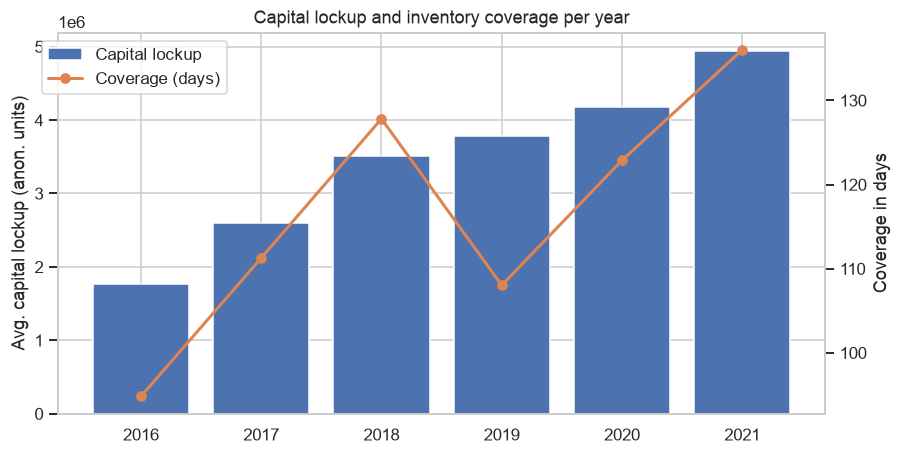

In [4]:
yearly_lockup = value.groupby(value.index.year).mean().sum(axis=1)

dem = tx[tx["entry_type"].isin(C.DEMAND_TYPES)].copy()
dem["value"] = dem["demand"] * dem["article_nr"].map(price)
yearly_consumption = dem.groupby(dem["date"].dt.year)["value"].sum()

trend = pd.DataFrame({"capital_lockup": yearly_lockup, "consumption_value": yearly_consumption}).loc[2016:2021]
trend["coverage_days"] = trend["capital_lockup"] / (trend["consumption_value"] / DPY)
trend["lockup_vs_2018_%"] = (trend["capital_lockup"] / trend.loc[2018, "capital_lockup"] * 100 - 100).round(1)
log("Capital lockup per year (inventory articles)", trend.round(1))

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(trend.index, trend["capital_lockup"], color="#4C72B0", label="Capital lockup")
ax1.set_ylabel("Avg. capital lockup (anon. units)")
ax2 = ax1.twinx()
ax2.plot(trend.index, trend["coverage_days"], color="#DD8452", marker="o", lw=2, label="Coverage (days)")
ax2.set_ylabel("Coverage in days"); ax2.grid(False)
ax1.set_title("Capital lockup and inventory coverage per year")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
savefig("03_capital_lockup_trend")

### 2b. Robustness check – does the stock method change the result?
51% of day transitions show a break, but positive and negative gaps almost cancel out. Alternative method:
rebuild stock from cumulated quantities, anchored at the last reported stock. If both methods give similar
yearly capital lockup, the conclusions don't depend on the break issue.

In [5]:
net_d = (daily.pivot(index="date", columns="article_nr", values="net")
              .reindex(index=stock.index, columns=stock.columns).fillna(0))
final = daily.groupby("article_nr")["closing"].last().reindex(stock.columns).values
recon = final - (net_d[::-1].cumsum()[::-1] - net_d)           # stock at end of each day
before_first = stock.index.values[:, None] < art["first_tx"].reindex(stock.columns).values[None, :]
recon = recon.mask(before_first, 0).clip(lower=0)
value_recon = recon * price.reindex(stock.columns).values

comp = pd.DataFrame({
    "reported_levels": value.groupby(value.index.year).mean().sum(axis=1),
    "rebuilt_from_quantities": value_recon.groupby(value_recon.index.year).mean().sum(axis=1),
}).loc[2016:2021]
comp["difference_%"] = (comp["rebuilt_from_quantities"] / comp["reported_levels"] * 100 - 100).round(1)
log("Capital lockup per year – two stock methods", comp.round(0))

a12 = value.loc[REF - pd.Timedelta(days=364):].mean()
b12 = value_recon.loc[REF - pd.Timedelta(days=364):].mean()
log("Last 12 months, per article: correlation between methods", f"{np.corrcoef(a12, b12)[0, 1]:.3f}")

gap_net = daily.groupby("article_nr")["gap"].sum() / typical
log("Net sum of gaps per article / typical stock", gap_net.describe().round(2))


=== Capital lockup per year – two stock methods ===
      reported_levels  rebuilt_from_quantities  difference_%
2016        1764859.0                2000726.0          13.0
2017        2601875.0                2497476.0          -4.0
2018        3514316.0                3768944.0           7.0
2019        3784867.0                3600209.0          -5.0
2020        4172666.0                4585596.0          10.0
2021        4944719.0                5236423.0           6.0

=== Last 12 months, per article: correlation between methods ===
0.954

=== Net sum of gaps per article / typical stock ===
count    1740.00
mean       -0.59
std         1.89
min       -46.56
25%        -0.93
50%        -0.07
75%         0.00
max         9.80


## 3. Where the capital sits today (last 12 months before the reference date)


=== Current capital lockup (avg. last 12 months) ===
4,958,257

=== Capital lockup by item_main_group ===
                         articles     lockup  share_%
item_main_group                                      
Item Main Group Code 2        107  1640597.0     33.0
Item Main Group Code 4        249  1405936.0     28.0
Item Main Group Code 6        271   588608.0     12.0
Item Main Group Code 8        158   401139.0      8.0
Item Main Group Code 7        284   356691.0      7.0
Item Main Group Code 5        113   210137.0      4.0
Item Main Group Code 1        506   198833.0      4.0
Item Main Group Code 9         47   134174.0      3.0
Item Main Group Code 3          9    17698.0      0.0
Item Main Group Code 10         7     4445.0      0.0

=== Capital lockup by submarket ===
              articles     lockup  share_%
submarket                                 
Submarket 1       1134  2675514.0     54.0
Submarket 15        71  1148769.0     23.0
Submarket 13        21   353913.0   

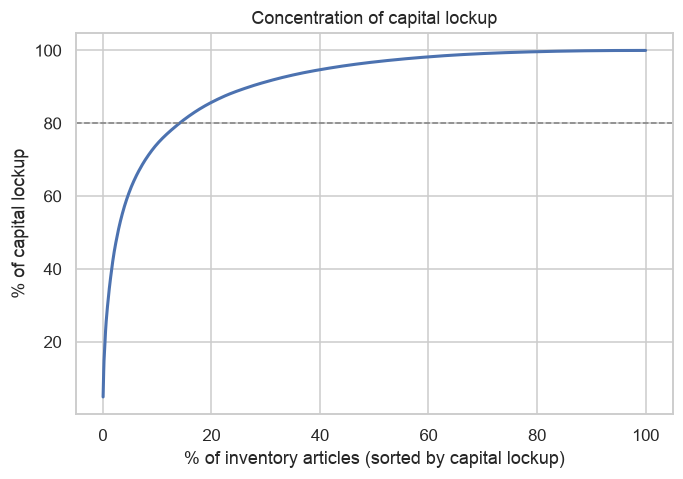

In [6]:
last12 = value.loc[REF - pd.Timedelta(days=364): REF]
art["lockup_12m"] = last12.mean().reindex(art.index).fillna(0)
art["stock_ref"] = stock.iloc[-1].reindex(art.index).fillna(0)
art["stock_value_ref"] = art["stock_ref"] * price
total_lockup = art["lockup_12m"].sum()
log("Current capital lockup (avg. last 12 months)", f"{total_lockup:,.0f}")

for col in ["item_main_group", "submarket", "eshop"]:
    g = art.groupby(col).agg(articles=("lockup_12m", "size"), lockup=("lockup_12m", "sum"))
    g["share_%"] = (g["lockup"] / total_lockup * 100).round(1)
    log(f"Capital lockup by {col}", g.sort_values("lockup", ascending=False).round(0))

srt = art["lockup_12m"].sort_values(ascending=False)
cum = srt.cumsum() / srt.sum()
pareto = pd.Series({f"top {p}% of articles": f"{cum.iloc[max(int(len(cum) * p / 100) - 1, 0)]:.1%} of capital"
                    for p in (1, 5, 10, 20, 50)})
log("Pareto – concentration of capital lockup", pareto)
log("Top 15 articles by capital lockup",
    art.loc[srt.index[:15], ["lockup_12m", "stock_ref", "last_direct_cost", "safety_stock", "moq", "lead_time"]].round(1))

plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, lw=2)
plt.axhline(80, ls="--", c="grey", lw=1)
plt.xlabel("% of inventory articles (sorted by capital lockup)"); plt.ylabel("% of capital lockup")
plt.title("Concentration of capital lockup")
savefig("03_pareto_capital_lockup")

## 4. Product type (derived from transactions)
The dataset has no product-type field, but the transactions reveal it:
- **finished product**: receives stock from own production (entry type 6)
- **semi-finished**: mostly consumed in production (usage share ≥ 50% of demand)
- **retail**: bought and sold without production

In [7]:
w = tx[tx["date"] <= REF]
has_prod_in = w.loc[w["entry_type"] == 6, "article_nr"].unique()
usage = w.loc[w["entry_type"] == 5].groupby("article_nr")["demand"].sum().clip(lower=0)
sales = w.loc[w["entry_type"] == 1].groupby("article_nr")["demand"].sum().clip(lower=0)
tot = usage.add(sales, fill_value=0)
art["usage_share"] = (usage / tot).reindex(art.index)

art["product_type"] = np.select(
    [art.index.isin(has_prod_in), art["usage_share"] >= 0.5, sales.reindex(art.index).fillna(0) > 0],
    ["finished", "semi-finished", "retail"], default="unclear (no demand)")
pt = art.groupby("product_type").agg(articles=("lockup_12m", "size"), lockup=("lockup_12m", "sum"))
pt["share_%"] = (pt["lockup"] / total_lockup * 100).round(1)
log("Product type (derived)", pt.round(0))


=== Product type (derived) ===
                     articles     lockup  share_%
product_type                                     
finished                  314   597841.0     12.0
retail                    369  1794019.0     36.0
semi-finished             854  2438478.0     49.0
unclear (no demand)       214   127919.0      3.0


## 5. ABC analysis – consumption value of the last 12 months
A = top 80% of consumption value, B = next 15%, C = last 5%, N = no consumption.

In [8]:
w12 = dem[(dem["date"] > REF - pd.Timedelta(days=365)) & (dem["date"] <= REF)]
cons12 = w12.groupby("article_nr")["value"].sum().clip(lower=0).reindex(art.index).fillna(0)
art["consumption_value_12m"] = cons12

s = cons12[cons12 > 0].sort_values(ascending=False)
cs = s.cumsum() / s.sum()
abc = pd.Series(np.where(cs <= 0.80, "A", np.where(cs <= 0.95, "B", "C")), index=s.index)
art["abc"] = abc.reindex(art.index).fillna("N")

t_abc = art.groupby("abc").agg(articles=("abc", "size"), consumption=("consumption_value_12m", "sum"),
                               lockup=("lockup_12m", "sum"))
t_abc["lockup_share_%"] = (t_abc["lockup"] / total_lockup * 100).round(1)
t_abc["coverage_days"] = (t_abc["lockup"] / (t_abc["consumption"] / DPY)).round(0)
log("ABC classes", t_abc.round(0))


=== ABC classes ===
     articles  consumption     lockup  lockup_share_%  coverage_days
abc                                                                 
A         169   10211202.0  3184583.0            64.0          112.0
B         298    1927388.0   809178.0            16.0          151.0
C         959     640463.0   712579.0            14.0          401.0
N         325          0.0   251917.0             5.0            inf


## 6. Demand patterns (monthly demand 2019–2021, outliers capped)
- **ADI** = average interval between months with demand (1 = every month)
- **CV²** = squared coefficient of variation of the non-zero demand sizes
- Syntetos–Boylan: smooth (ADI < 1.32, CV² < 0.49), erratic, intermittent, lumpy
- **XYZ** on the CV of monthly demand incl. zeros: X < 0.5, Y < 1.0, Z ≥ 1.0

Smooth ≈ the case study's "basic demand"; intermittent/lumpy ≈ "searched demand".


=== Demand patterns (Syntetos-Boylan) ===
              articles     lockup  lockup_share_%
pattern                                          
erratic            400  1494271.0            30.0
intermittent       289   490158.0            10.0
lumpy              612  1015511.0            20.0
no demand          253   145326.0             3.0
smooth             197  1812991.0            37.0

=== ABC-XYZ: number of articles ===
xyz   X    Y    Z    -
abc                   
A    31   77   61    0
B    23   99  176    0
C    15  154  789    1
N     0    2   71  252

=== ABC-XYZ: share of capital lockup (%) ===
xyz     X     Y     Z    -
abc                       
A    14.7  27.9  21.6  0.0
B     2.1   5.3   8.9  0.0
C     0.2   2.0  12.2  0.0
N     0.0   0.2   1.9  2.9


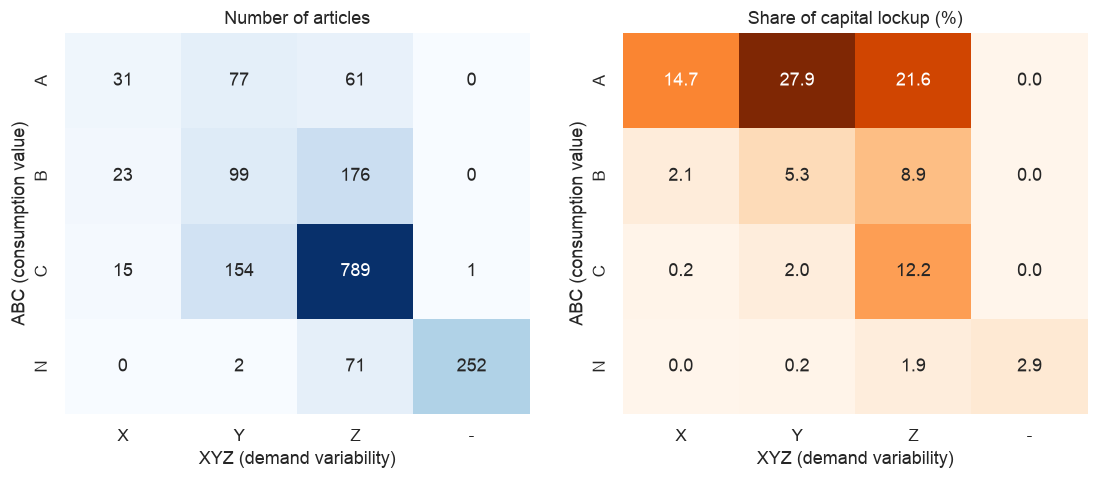

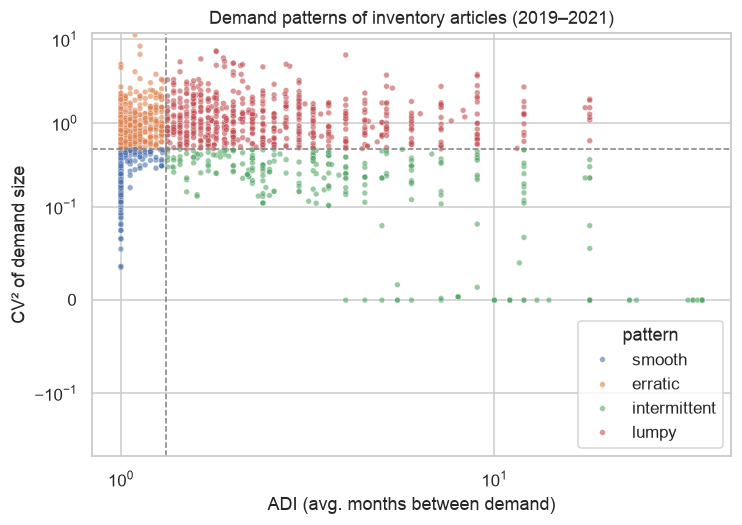

In [9]:
obs = dm.dropna(subset=["demand_capped"])
g = obs.groupby("article_nr")["demand_capped"]
nz = obs[obs["demand_capped"] > 0].groupby("article_nr")["demand_capped"]

feat = pd.DataFrame({
    "months_observed": g.size(), "months_with_demand": nz.size(),
    "mean_monthly": g.mean(), "std_monthly": g.std(),
    "mean_monthly_raw": obs.groupby("article_nr")["demand_raw"].mean(),
    "std_monthly_raw": obs.groupby("article_nr")["demand_raw"].std(),
    "nz_mean": nz.mean(), "nz_std": nz.std(),
}).reindex(art.index)
feat["months_with_demand"] = feat["months_with_demand"].fillna(0)
feat["adi"] = feat["months_observed"] / feat["months_with_demand"].replace(0, np.nan)
feat["cv2"] = ((feat["nz_std"] / feat["nz_mean"]) ** 2).fillna(0)
feat["cv"] = feat["std_monthly"] / feat["mean_monthly"].replace(0, np.nan)
art = art.join(feat.drop(columns=["nz_mean", "nz_std"]))

art["pattern"] = np.select(
    [art["months_with_demand"] == 0,
     (art["adi"] < 1.32) & (art["cv2"] < 0.49), (art["adi"] < 1.32),
     (art["cv2"] < 0.49)],
    ["no demand", "smooth", "erratic", "intermittent"], default="lumpy")
art["xyz"] = np.select([art["cv"].isna(), art["cv"] < 0.5, art["cv"] < 1.0], ["-", "X", "Y"], default="Z")
art["flag_short_history"] = art["months_observed"].fillna(0) < 12

pat = art.groupby("pattern").agg(articles=("pattern", "size"), lockup=("lockup_12m", "sum"))
pat["lockup_share_%"] = (pat["lockup"] / total_lockup * 100).round(1)
log("Demand patterns (Syntetos-Boylan)", pat.round(0))

m_n = pd.crosstab(art["abc"], art["xyz"]).reindex(index=["A", "B", "C", "N"], columns=["X", "Y", "Z", "-"], fill_value=0)
m_v = (art.pivot_table(index="abc", columns="xyz", values="lockup_12m", aggfunc="sum", fill_value=0)
          .reindex(index=["A", "B", "C", "N"], columns=["X", "Y", "Z", "-"], fill_value=0) / total_lockup * 100)
log("ABC-XYZ: number of articles", m_n)
log("ABC-XYZ: share of capital lockup (%)", m_v.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(m_n, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Number of articles")
sns.heatmap(m_v, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1], cbar=False)
axes[1].set_title("Share of capital lockup (%)")
for a in axes: a.set_xlabel("XYZ (demand variability)"); a.set_ylabel("ABC (consumption value)")
savefig("03_abc_xyz_matrix")

p = art[art["pattern"] != "no demand"]
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=p, x="adi", y="cv2", hue="pattern", s=14, alpha=0.6,
                hue_order=["smooth", "erratic", "intermittent", "lumpy"])
plt.axvline(1.32, ls="--", c="grey", lw=1); plt.axhline(0.49, ls="--", c="grey", lw=1)
plt.xscale("log"); plt.yscale("symlog", linthresh=0.1)
plt.xlabel("ADI (avg. months between demand)"); plt.ylabel("CV² of demand size")
plt.title("Demand patterns of inventory articles (2019–2021)")
savefig("03_demand_patterns")

## 7. Dead and slow-moving stock (time since last sale/usage)


=== Time since last demand (at reference date) ===
                    articles  stock_value_ref  lockup_12m  lockup_share_%
last_demand_bucket                                                       
<1 year                 1429        4678532.0   4706826.0            95.0
1-2 years                 55          91751.0     98038.0             2.0
2-3 years                 15          10152.0      8071.0             0.0
3-4 years                  5           8429.0      8424.0             0.0
4-5 years                  5           7155.0      1166.0             0.0
>5 years                  27           9851.0      7352.0             0.0
never                    215         169670.0    128382.0             3.0


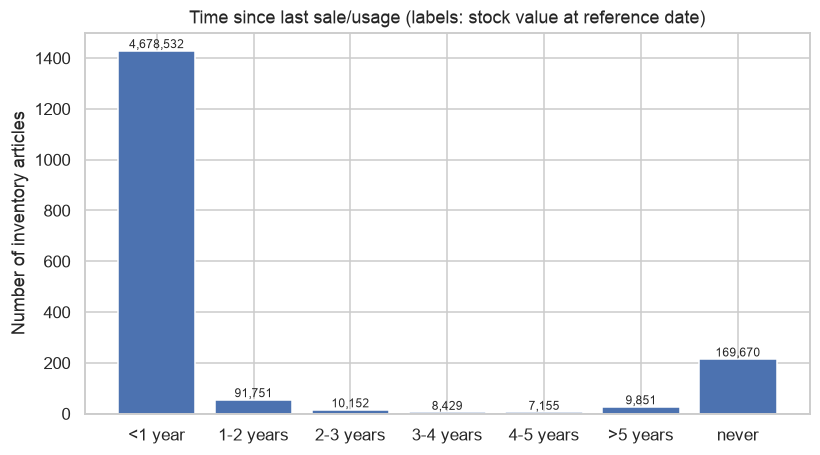

In [10]:
bins = [-np.inf, 365, 730, 1095, 1460, 1825, np.inf]
labels = ["<1 year", "1-2 years", "2-3 years", "3-4 years", "4-5 years", ">5 years"]
art["last_demand_bucket"] = pd.cut(art["days_since_demand"], bins=bins, labels=labels).astype(str)
art.loc[art["days_since_demand"].isna(), "last_demand_bucket"] = "never"
order = labels + ["never"]

ds = art.groupby("last_demand_bucket").agg(articles=("lockup_12m", "size"),
                                           stock_value_ref=("stock_value_ref", "sum"),
                                           lockup_12m=("lockup_12m", "sum")).reindex(order).fillna(0)
ds["lockup_share_%"] = (ds["lockup_12m"] / total_lockup * 100).round(1)
log("Time since last demand (at reference date)", ds.round(0))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(ds.index, ds["articles"], color="#4C72B0")
for b, v in zip(bars, ds["stock_value_ref"]):
    ax.annotate(f"{v:,.0f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Number of inventory articles")
ax.set_title("Time since last sale/usage (labels: stock value at reference date)")
savefig("03_last_demand")

## 8. Lead time


=== Lead time (days, maintained only) ===
count    1714.0
mean       26.8
std        20.5
min         1.0
25%        15.0
50%        30.0
75%        30.0
max       240.0

=== Most common lead times ===
lead_time
30     553
15     381
10     226
45     197
5      157
60      82
20      48
0       37
90      32
120     17

=== Median lead time by main group ===
item_main_group
Item Main Group Code 1     10.0
Item Main Group Code 10    20.0
Item Main Group Code 2     45.0
Item Main Group Code 3     20.0
Item Main Group Code 4     30.0
Item Main Group Code 5     30.0
Item Main Group Code 6     15.0
Item Main Group Code 7     30.0
Item Main Group Code 8     20.0
Item Main Group Code 9     45.0


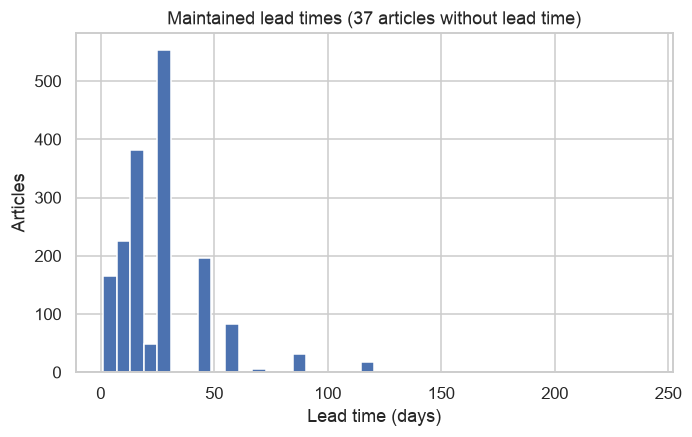

In [11]:
lt = art.loc[art["lead_time"] > 0, "lead_time"]
log("Lead time (days, maintained only)", lt.describe().round(1))
log("Most common lead times", art["lead_time"].value_counts().head(10))
log("Median lead time by main group", art[art["lead_time"] > 0].groupby("item_main_group")["lead_time"].median())

plt.figure(figsize=(7, 4))
plt.hist(lt, bins=40, color="#4C72B0")
plt.xlabel("Lead time (days)"); plt.ylabel("Articles")
plt.title(f"Maintained lead times ({(art['lead_time'] == 0).sum()} articles without lead time)")
savefig("03_lead_time")

## 9. Current reorder point and MOQ vs. actual demand
`safety_stock` is used as the **reorder point** by the company. A reorder point should roughly cover
demand during the lead time plus a buffer, so:

- **ROP ratio** = current reorder point / (daily demand × lead time). ≈ 1–2 is plausible, > 2 suggests oversizing.
- **MOQ coverage** = minimum order quantity / monthly demand. Large values mean stock is driven by order size, not by the reorder point.


=== Current reorder point vs. lead-time demand ===
                          articles     lockup  lockup_share_%
rop_ratio                                                    
<0.5 (undersized)             91.0  1159446.0            23.0
0.5-1                        126.0   841300.0            17.0
1-2 (plausible)              232.0   626853.0            13.0
2-4                          309.0   989088.0            20.0
4-10                         266.0   738179.0            15.0
>10 (heavily oversized)      441.0   438102.0             9.0
no demand / no lead time     286.0   165289.0             3.0

=== Reorder point coverage in days (median by ABC) ===
abc
A     47.0
B     44.0
C    123.0
N    540.0

=== MOQ in months of demand (MOQ maintained, demand > 0) ===
moq_months
<1 month      159
1-3           316
3-6           203
6-12          159
>12 months    281


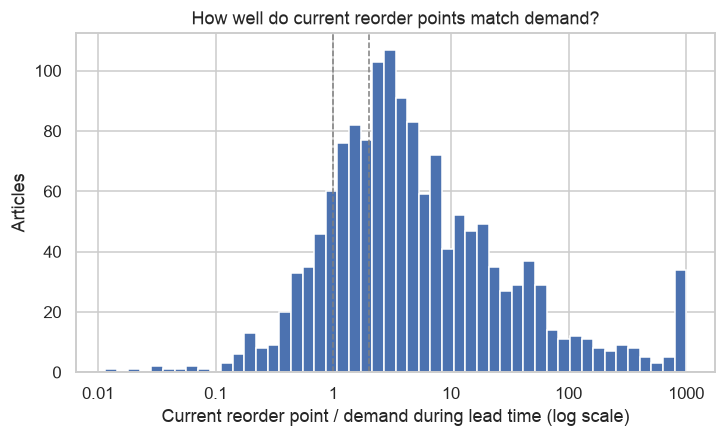

In [12]:
art["daily_demand"] = art["mean_monthly"] * 12 / DPY
lt_dem = art["daily_demand"] * art["lead_time"]
art["rop_ratio"] = art["safety_stock"] / lt_dem.where(lt_dem > 0)
art["rop_coverage_days"] = art["safety_stock"] / art["daily_demand"].where(art["daily_demand"] > 0)
art["moq_months"] = art["moq"] / art["mean_monthly"].where(art["mean_monthly"] > 0)
art.loc[art["moq"] == 0, "moq_months"] = np.nan

rb = pd.cut(art["rop_ratio"], [0, 0.5, 1, 2, 4, 10, np.inf],
            labels=["<0.5 (undersized)", "0.5-1", "1-2 (plausible)", "2-4", "4-10", ">10 (heavily oversized)"],
            include_lowest=True)
rop_t = art.groupby(rb, observed=False).agg(articles=("lockup_12m", "size"), lockup=("lockup_12m", "sum"))
rop_t.loc["no demand / no lead time"] = [art["rop_ratio"].isna().sum(), art.loc[art["rop_ratio"].isna(), "lockup_12m"].sum()]
rop_t["lockup_share_%"] = (rop_t["lockup"] / total_lockup * 100).round(1)
log("Current reorder point vs. lead-time demand", rop_t.round(0))
log("Reorder point coverage in days (median by ABC)", art.groupby("abc")["rop_coverage_days"].median().round(0))

mb = pd.cut(art["moq_months"], [0, 1, 3, 6, 12, np.inf], labels=["<1 month", "1-3", "3-6", "6-12", ">12 months"])
log("MOQ in months of demand (MOQ maintained, demand > 0)", mb.value_counts().sort_index())

plt.figure(figsize=(7.5, 4))
plt.hist(np.log10(art["rop_ratio"].dropna().clip(1e-2, 1e3)), bins=50, color="#4C72B0")
for x in (0, np.log10(2)): plt.axvline(x, ls="--", c="grey", lw=1)
plt.xticks([-2, -1, 0, 1, 2, 3], ["0.01", "0.1", "1", "10", "100", "1000"])
plt.xlabel("Current reorder point / demand during lead time (log scale)"); plt.ylabel("Articles")
plt.title("How well do current reorder points match demand?")
savefig("03_rop_ratio")

## 10. Save feature table

In [13]:
art["age_days"] = (REF - art["first_tx"]).dt.days
art.reset_index().to_parquet(C.ARTICLE_FEATURES, index=False)
log("Saved", f"{C.ARTICLE_FEATURES.name} | {art.shape[0]:,} articles x {art.shape[1]} columns")
log("Feature columns", ", ".join(art.columns))

out_file = C.TABLES / "03_analysis_summary.txt"
out_file.write_text("\n".join(summary), encoding="utf-8")
print(f"Summary written to {out_file} – share this file (figures are in outputs/figures/).")


=== Saved ===
article_features.parquet | 1,751 articles x 48 columns

=== Feature columns ===
safety_stock, lead_time, moq, last_direct_cost, vendor_nr, base_unit, eshop, submarket, item_main_group, item_sub_group, item_category, product_category, inventory_level_latest_row, first_tx, last_demand, days_since_demand, flag_no_demand, flag_lead_time_missing, flag_price_zero, flag_moq_missing, flag_negative_stock, flag_new_in_window, n_outliers_capped, lockup_12m, stock_ref, stock_value_ref, usage_share, product_type, consumption_value_12m, abc, months_observed, months_with_demand, mean_monthly, std_monthly, mean_monthly_raw, std_monthly_raw, adi, cv2, cv, pattern, xyz, flag_short_history, last_demand_bucket, daily_demand, rop_ratio, rop_coverage_days, moq_months, age_days
Summary written to /Users/nikolaosgeorgantopoulos/Repositories/inventory-optimization/outputs/tables/03_analysis_summary.txt – share this file (figures are in outputs/figures/).
